In [1]:
%cd ..
import os, sys
# Must be set before pyproj is imported on Windows
os.environ["PROJ_DATA"] = os.path.join(sys.prefix, "Library", "share", "proj")

C:\Users\yvjennig\PycharmProjects\github\time_imputation


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyproj import Transformer
from skgstat import Variogram
from statsmodels.tsa.stattools import acf

import config
from utils.data import load_dataset

%matplotlib inline
sns.set_theme(style="whitegrid")

C:\Users\yvjennig\Anaconda3\envs\time_imputation\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [3]:
# Load data
df = load_dataset()

# Ensure output dirs exist
os.makedirs(config.output_dir_correlations, exist_ok=True)

# Variogram Analysis

P_TEMPERATURE


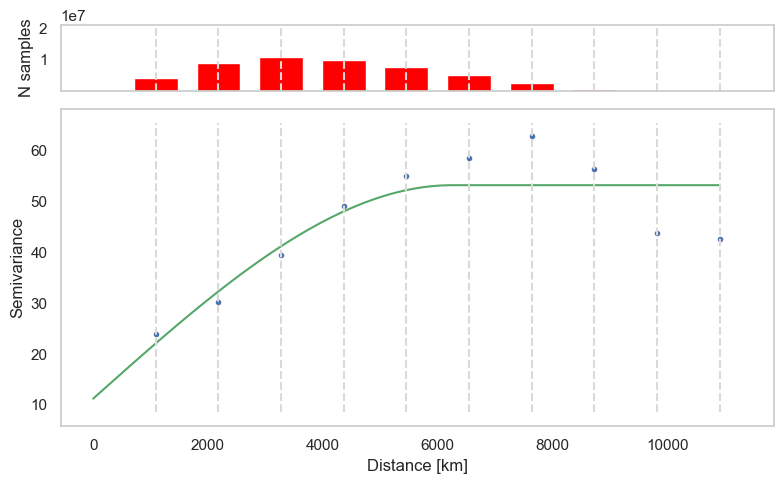

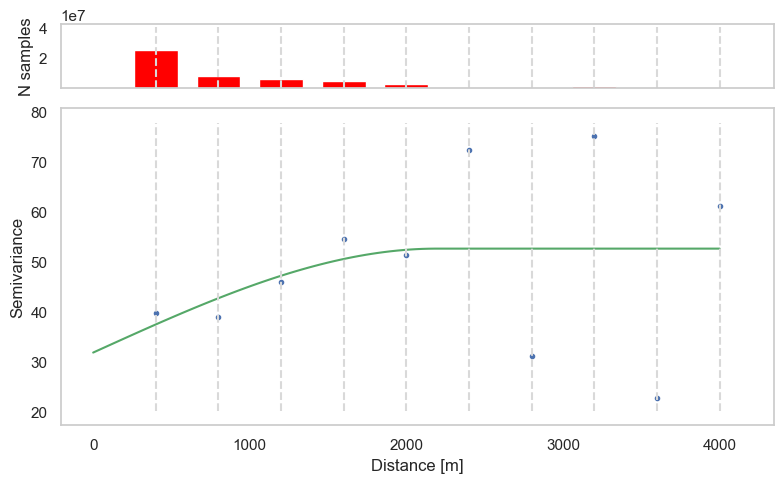

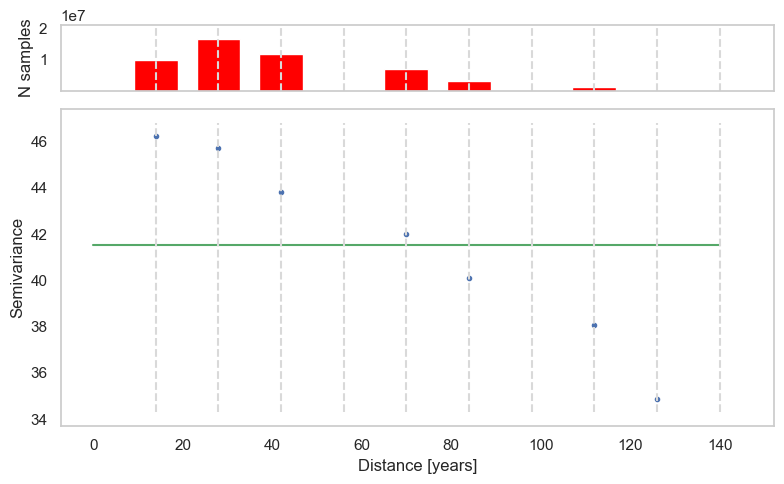

P_SALINITY


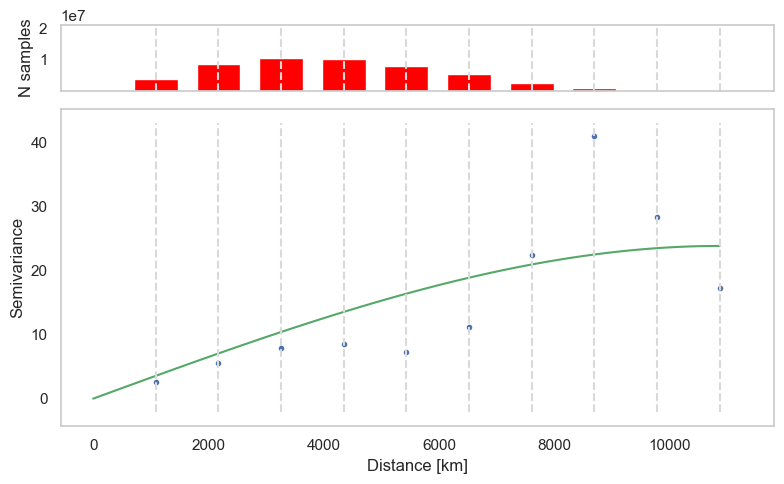

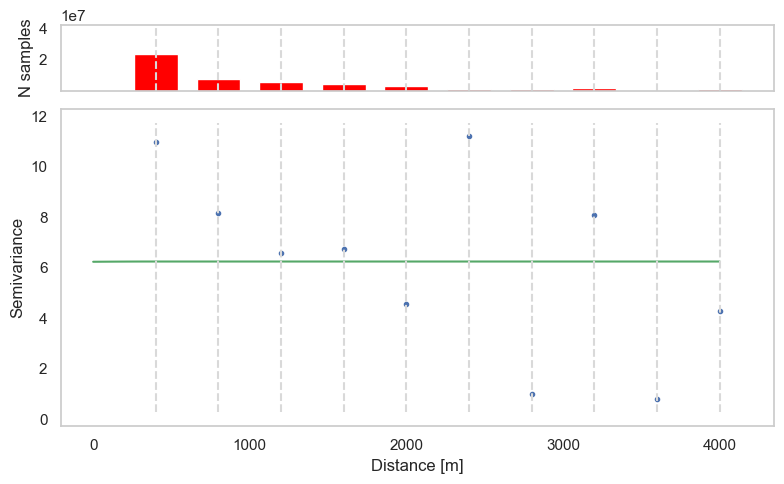

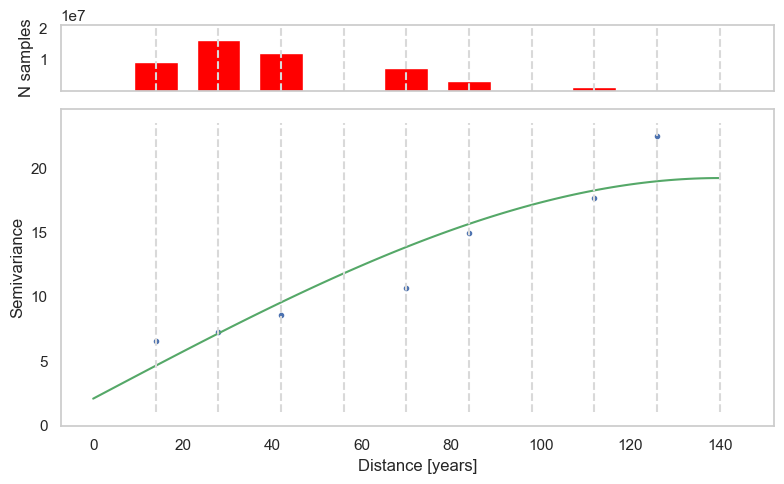

P_OXYGEN


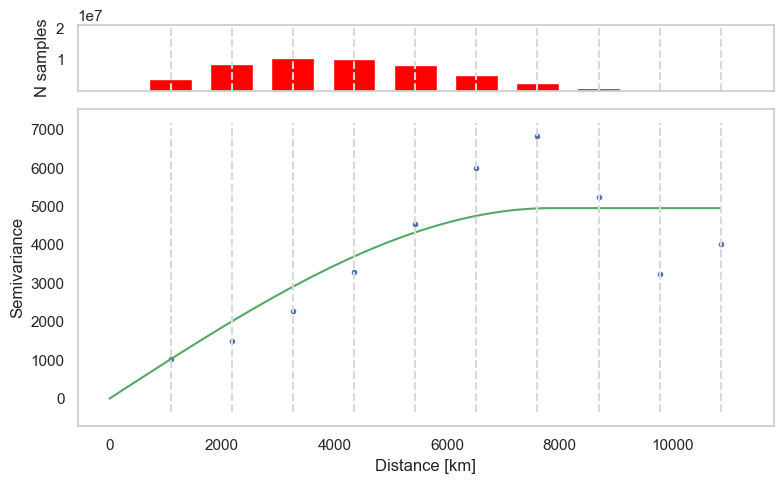

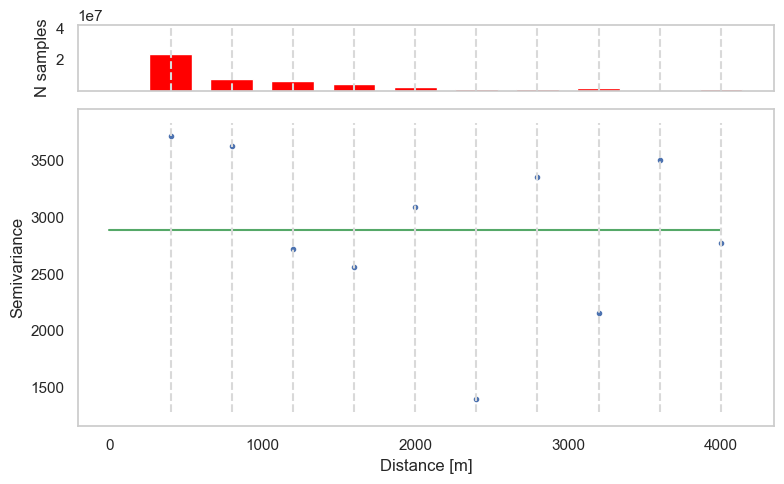

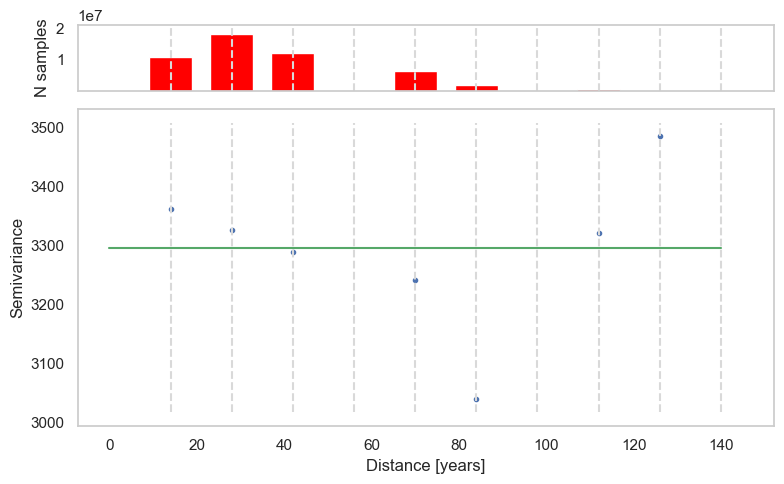

P_NITRATE


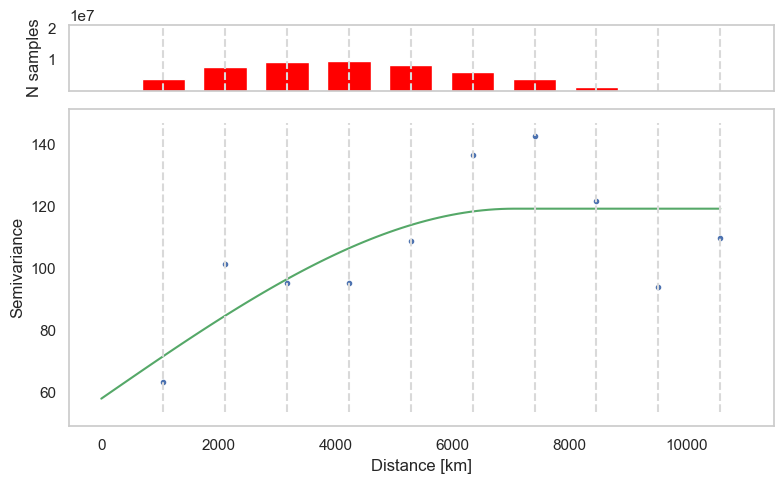

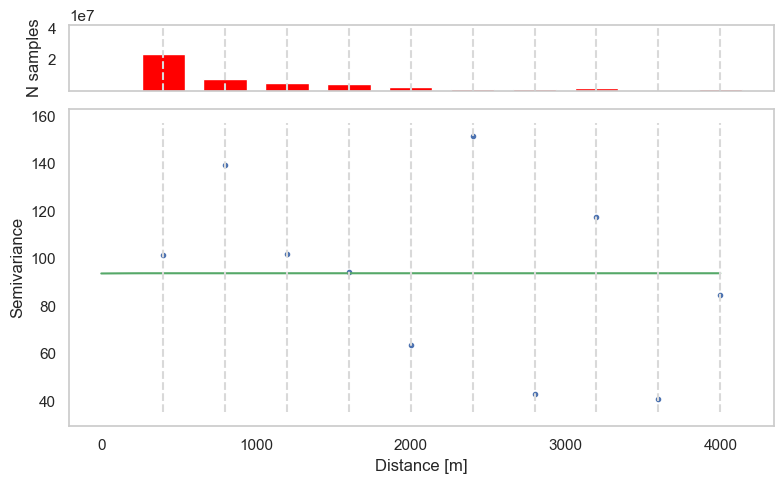

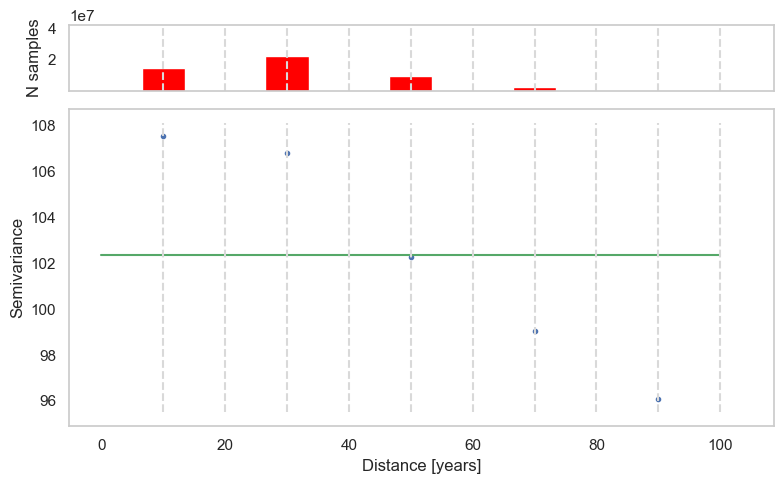

P_SILICATE


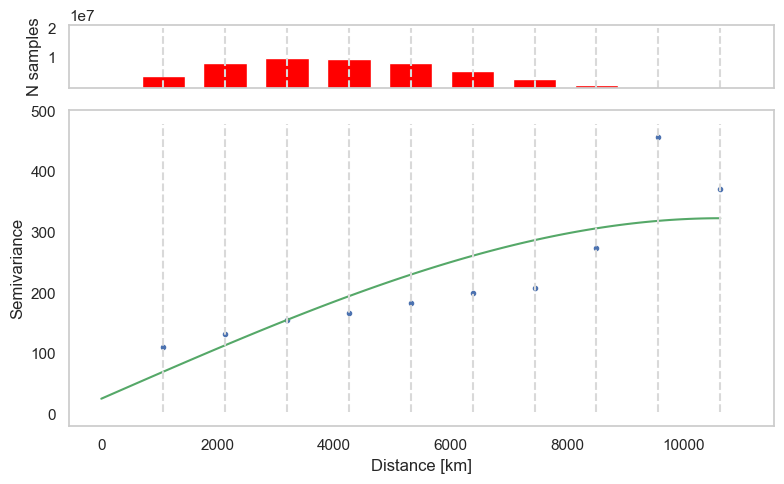

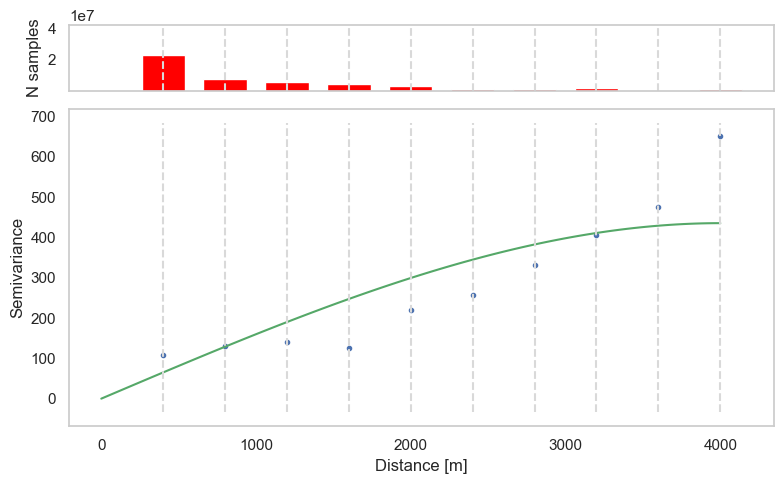

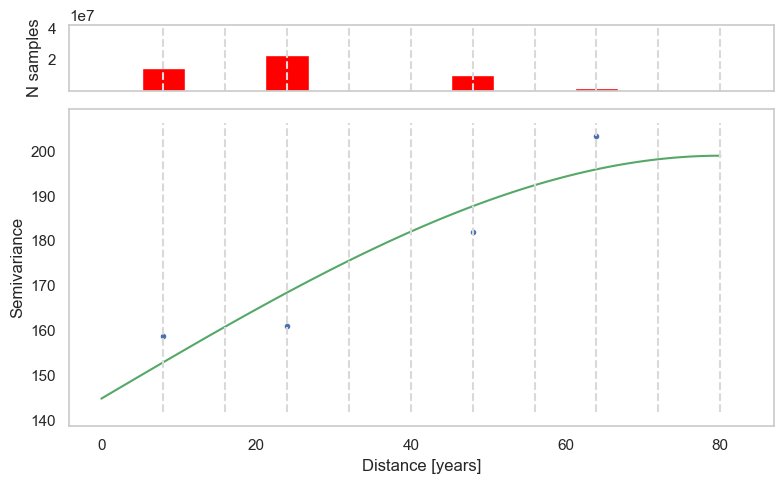

P_PHOSPHATE


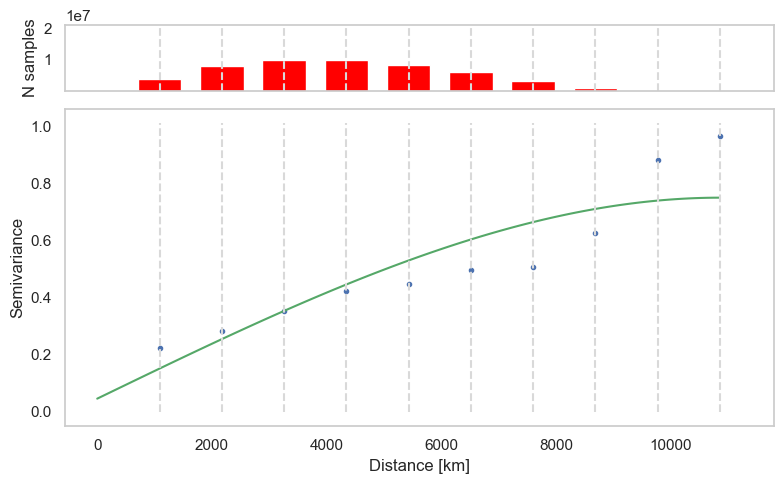

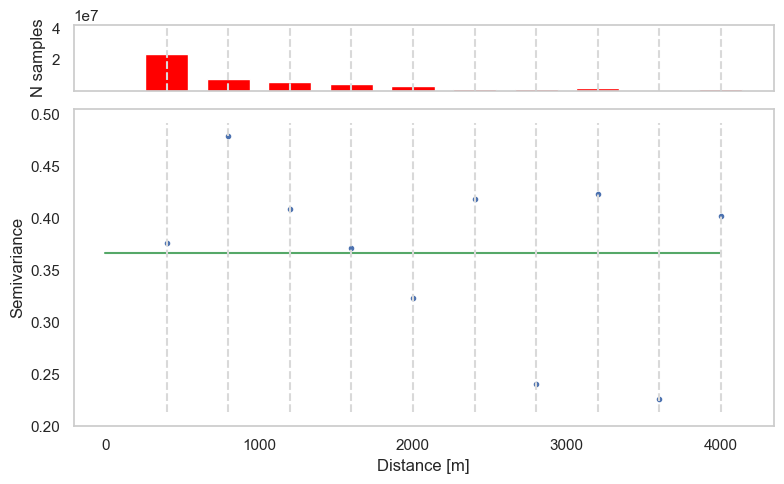

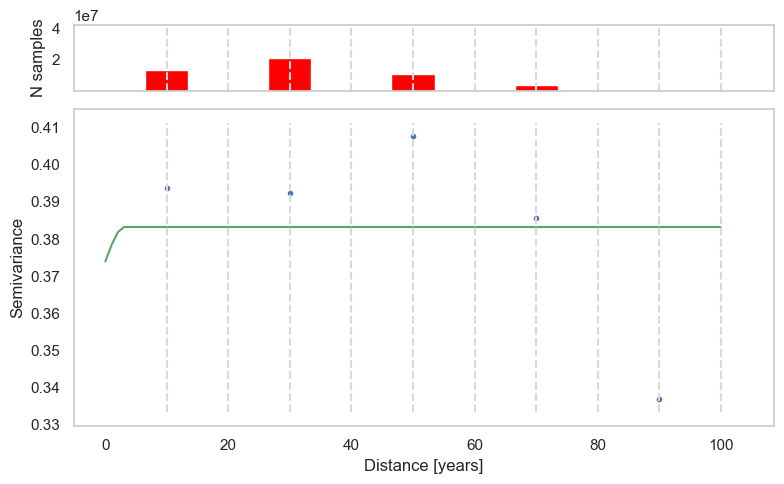

In [4]:
decorrelation_ranges = []

for param in config.parameters:
    print(param)
    # Subsample for computational tractability
    df_sub = df[["LONGITUDE", "LATITUDE", "LEV_M", "DATEANDTIME", param]].dropna().sample(n=10000, random_state=42)

    # Project lat/lon to metric distances (Lambert Azimuthal Equal Area, centred on the data)
    transformer = Transformer.from_crs(
        "+proj=longlat +datum=WGS84",
        f"+proj=laea +lat_0={df_sub['LATITUDE'].mean()} +lon_0={df_sub['LONGITUDE'].mean()} +datum=WGS84 +units=m +no_defs",
        always_xy=True,
    )
    x, y = transformer.transform(df_sub["LONGITUDE"], df_sub["LATITUDE"])
    df_sub["LONGITUDE"] = x / 1000  # metres → km
    df_sub["LATITUDE"] = y / 1000

    # Fit variograms along the three independent dimensions
    spatial_v = Variogram(coordinates=df_sub[["LONGITUDE", "LATITUDE"]].values, values=df_sub[param].values, use_nugget=True)
    depth_v   = Variogram(coordinates=df_sub[["LEV_M"]].values,      values=df_sub[param].values, use_nugget=True)
    time_v    = Variogram(coordinates=df_sub[["DATEANDTIME"]].values, values=df_sub[param].values, use_nugget=True)

    for v, xlabel, fname in [
        (spatial_v, "Distance [km]",    f"spatial_variogram_{param}.png"),
        (depth_v,   "Distance [m]",     f"depth_variogram_{param}.png"),
        (time_v,    "Distance [years]", f"time_variogram_{param}.png"),
    ]:
        fig = v.plot()
        fig.axes[1].set_ylabel("N samples")
        fig.axes[0].set_xlabel(xlabel)
        fig.axes[0].set_ylabel("Semivariance")
        plt.tight_layout()
        # plt.savefig(os.path.join(config.output_dir_high_res_plots, fname), dpi=300)
        plt.show()

    spatial_range, spatial_sill, spatial_nugget = spatial_v.parameters
    depth_range,   depth_sill,   depth_nugget   = depth_v.parameters
    time_range,    time_sill,    time_nugget     = time_v.parameters

    decorrelation_ranges.append(pd.DataFrame({
        "parameter":      [param],
        "spatial_range":  [spatial_range],  "spatial_sill":  [spatial_sill],  "spatial_nugget":  [spatial_nugget],
        "depth_range":    [depth_range],    "depth_sill":    [depth_sill],    "depth_nugget":    [depth_nugget],
        "time_range":     [time_range],     "time_sill":     [time_sill],     "time_nugget":     [time_nugget],
    }))

df_decorrelation_ranges = pd.concat(decorrelation_ranges, ignore_index=True)
df_decorrelation_ranges.to_csv(os.path.join(config.output_dir_correlations, "variogram_data.csv"), index=False)

In [5]:
df_decorrelation_ranges

,parameter,spatial_range,spatial_sill,spatial_nugget,depth_range,depth_sill,depth_nugget,time_range,time_sill,time_nugget
0,P_TEMPERATURE,6245.842054,41.954934,1.123028e+01,2192.188742,2.083228e+01,3.171859e+01,140.000000,1.192765e-11,41.543499
1,P_SALINITY,10869.071490,23.861041,1.729531e-12,358.173044,9.853746e-03,6.239206e+00,140.000000,1.715340e+01,2.080286
2,P_OXYGEN,7845.076383,4956.074841,3.105042e-08,4000.000000,2.184570e-13,2.892459e+03,140.000000,3.816448e-11,3294.862848
3,P_NITRATE,7050.904089,61.242182,5.816089e+01,302.948500,9.137639e-02,9.379390e+01,100.000000,2.474298e-12,102.348709
4,P_SILICATE,10630.573233,297.678668,2.580413e+01,4000.000000,4.356370e+02,2.991472e-15,80.000000,5.411715e+01,144.867735
5,P_PHOSPHATE,10860.163652,0.705866,4.565284e-02,4000.000000,1.178770e-12,3.671280e-01,3.059205,9.274709e-03,0.373966


## Results Table

In [6]:
# Beautify naming
df_decorrelation_ranges["parameter"] = df_decorrelation_ranges["parameter"].map(config.parameter_name_map)
df_decorrelation_ranges = df_decorrelation_ranges.rename(columns={"spatial_range": "Spatial range", "spatial_sill": "Spatial sill", "spatial_nugget": "Spatial nugget",
       "depth_range": "Depth range", "depth_sill": "Depth sill", "depth_nugget": "Depth nugget", "time_range": "Time range", "time_sill": "Time sill",
       "time_nugget":"Time nugget"})

formatters = {
        "Spatial range": "{:.0f}".format,
        "Spatial sill": "{:.1f}".format,
        "Spatial nugget": "{:.1f}".format,
        "Depth range": "{:.0f}".format,
        "Depth sill": "{:.1f}".format,
        "Depth nugget": "{:.1f}".format,
        "Time range": "{:.0f}".format,
        "Time sill": "{:.1f}".format,
        "Time nugget": "{:.1f}".format
    }

In [7]:
df_formatted = df_decorrelation_ranges.copy()
for col, fmt in formatters.items():
    df_formatted[col] = df_formatted[col].map(fmt)

# Transpose so parameters are columns and statistics are rows
df_transposed = df_formatted.set_index("parameter").T
n_params = len(df_transposed.columns)
tex_table = df_transposed.to_latex(
    index=True,
    column_format="l|" + "r" * n_params,
    caption="Summary of variogram statistics per parameter",
    label="tab:variogram_results",
)

# Replace the rule-separated first header cell with \multicolumn to avoid a double vertical line
lines = tex_table.split("\n")
header_idx = next(i + 1 for i, l in enumerate(lines) if "\\toprule" in l)
header = lines[header_idx]
sep = header.index("&")
first_cell = header[:sep].strip()
lines[header_idx] = f"\\multicolumn{{1}}{{l}}{{{first_cell}}} &" + header[sep + 1:]
print("\n".join(lines))

\begin{table}
\caption{Summary of variogram statistics per parameter}
\label{tab:variogram_results}
\begin{tabular}{l|rrrrrr}
\toprule
\multicolumn{1}{l}{parameter} & Potential temperature & Salinity & Oxygen & Nitrate & Silicate & Phosphate \\
\midrule
Spatial range & 6246 & 10869 & 7845 & 7051 & 10631 & 10860 \\
Spatial sill & 42.0 & 23.9 & 4956.1 & 61.2 & 297.7 & 0.7 \\
Spatial nugget & 11.2 & 0.0 & 0.0 & 58.2 & 25.8 & 0.0 \\
Depth range & 2192 & 358 & 4000 & 303 & 4000 & 4000 \\
Depth sill & 20.8 & 0.0 & 0.0 & 0.1 & 435.6 & 0.0 \\
Depth nugget & 31.7 & 6.2 & 2892.5 & 93.8 & 0.0 & 0.4 \\
Time range & 140 & 140 & 140 & 100 & 80 & 3 \\
Time sill & 0.0 & 17.2 & 0.0 & 0.0 & 54.1 & 0.0 \\
Time nugget & 41.5 & 2.1 & 3294.9 & 102.3 & 144.9 & 0.4 \\
\bottomrule
\end{tabular}
\end{table}



# Temporal Autocorrelation

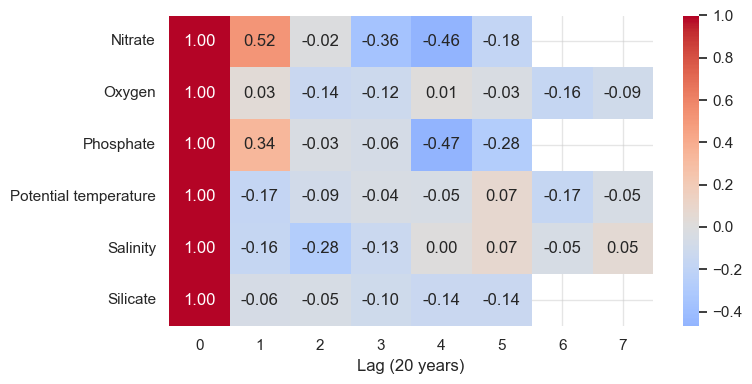

In [8]:
temporal_autocorrelations = []

for param in config.parameters:
    # Average over all locations per time step before computing ACF to isolate the temporal signal
    time_means = df[["DATEANDTIME", param]].dropna().groupby("DATEANDTIME")[param].mean()
    acf_vals = acf(time_means.values, fft=True)
    temporal_autocorrelations.append(
        pd.DataFrame({"parameter": [param] * len(acf_vals), "acf": acf_vals, "lag": range(len(acf_vals))})
    )

df_autocorr = pd.concat(temporal_autocorrelations, ignore_index=True)
df_autocorr.to_csv(os.path.join(config.output_dir_correlations, "temporal_autocorrelations.csv"), index=False)

pivot = df_autocorr.copy()
pivot["parameter"] = pivot["parameter"].map(config.parameter_name_map)
pivot = pivot.groupby(["parameter", "lag"])["acf"].mean().unstack()

plt.figure(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.xlabel("Lag (20 years)")
plt.ylabel("")
plt.tight_layout()
plt.savefig(os.path.join(config.output_dir_high_res_plots, "temporal_autocorrelation.png"), dpi=300)
plt.show()